# Ensambles de Modelos con Datos de Rendimiento Académico
## Bagging, Random Forest, AdaBoost, Gradient Boosting y XGBoost

**Machine Learning 1 — FIUNA**

**Docente:** Diego Stalder | **Práctica:** Carlos Benítez

---

## Objetivo

Aplicar los **métodos de ensamble** vistos en la teoría al dataset académico real (Ecuaciones Diferenciales → Cálculo 2), prediciendo la variable binaria **`Remontada`**.

Compararemos:
- **Modelos base:** árbol de decisión, regresión logística, SVM
- **Bagging:** Bagging de árboles, Random Forest, Extra Trees
- **Boosting:** AdaBoost, Gradient Boosting, XGBoost

## Estructura

1. **Carga y preparación** del dataset académico
2. **Baselines:** Regresión Logística, SVM, Árbol individual
3. **Bagging:** Bagging Classifier y Random Forest
4. **Extra Trees:** Random Forest más aleatorizado
5. **AdaBoost** con árboles débiles
6. **Gradient Boosting**
7. **XGBoost**
8. **Comparación completa** con curvas ROC
9. **Importancia de características**
10. **Interpretación pedagógica**

## 0. Importaciones y Configuración

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Baselines
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Ensambles de Bagging
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier
)

# Ensambles de Boosting
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
import xgboost as xgb

# Métricas
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)

# Configuración visual
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'font.size': 11,
    'axes.grid': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 100
})
sns.set_palette('husl')
np.random.seed(42)

print("="*80)
print("🎯 ENSAMBLES DE MODELOS — Datos Académicos Reales")
print("="*80)
print(f"XGBoost versión: {xgb.__version__}")

🎯 ENSAMBLES DE MODELOS — Datos Académicos Reales
XGBoost versión: 3.0.5


## 1. Carga y Preparación del Dataset

Usamos el mismo pipeline de las clases anteriores: Ecuaciones Diferenciales como materia previa, Cálculo 2 como materia siguiente, con la variable objetivo `Remontada`.

In [18]:
# Cargar datos
df = pd.read_csv(r'D:\ArchivosHDD\GitHub\Machine-Learning\Clase_4\datos_concatenados.csv')
print(f"✅ Datos cargados: {len(df):,} registros")

# Filtrar Ecuaciones Diferenciales
mask_ed = df['Asignatura'].str.upper().str.contains('ECUACIONES DIFERENCIALES', na=False)
df_ed = df[mask_ed].copy()

# Filtrar Cálculo 2
mask_c2 = df['Asignatura'].str.upper().str.contains('CALCULO 2', na=False)
df_c2 = df[mask_c2].copy()

# Variable objetivo: Remontada
df_ed['Remontada'] = (df_ed['Segundo.Par'] > df_ed['Primer.Par']) & (df_ed['Firma'] > 50)

# Merge por alumno
merged = df_ed.merge(df_c2, on='ALUMNO_ID', how='inner', suffixes=('_ed', '_c2'))
print(f"Registros después del merge: {len(merged):,}")

# Features
feature_cols = [
    'Primer.Par_ed', 'Segundo.Par_ed', 'Tercer.Par_ed',
    'TPLab._ed', 'Lab._ed', 'Proy._ed',
    'Asis_ed', 'Requisito_ed', 'Firma_ed',
    'Primer.Rec_ed', 'Segundo.Rec_ed',
]

X = merged[feature_cols].copy()
y = merged['Remontada'].astype(int)

# Convertir a numérico y limpiar
for col in feature_cols:
    X[col] = pd.to_numeric(X[col], errors='coerce')

mask_valid = ~X.isnull().any(axis=1)
X = X[mask_valid].reset_index(drop=True)
y = y[mask_valid].reset_index(drop=True)

print(f"\n📊 Dataset final: {len(X)} estudiantes, {X.shape[1]} características")
print(f"Tasa de Remontada: {y.mean()*100:.1f}%")
print(f"Distribución de clases:")
print(y.value_counts())

# Split estratificado
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"\nEntrenamiento: {len(X_train)} | Prueba: {len(X_test)}")

✅ Datos cargados: 72,740 registros
Registros después del merge: 304

📊 Dataset final: 304 estudiantes, 11 características
Tasa de Remontada: 9.2%
Distribución de clases:
Remontada
0    276
1     28
Name: count, dtype: int64

Entrenamiento: 212 | Prueba: 92


## 2. Baselines: Modelos Individuales

Entrenamos los modelos individuales de las clases anteriores para tener una **referencia de comparación**.

In [19]:
# Diccionario para almacenar resultados
resultados = {}

def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_te, y_te):
    """Entrena, evalúa y almacena resultados de un modelo."""
    t0 = time.time()
    modelo.fit(X_tr, y_tr)
    t_train = time.time() - t0
    
    y_pred = modelo.predict(X_te)
    y_prob = modelo.predict_proba(X_te)[:, 1] if hasattr(modelo, 'predict_proba') else modelo.decision_function(X_te)
    
    resultados[nombre] = {
        'modelo': modelo,
        'accuracy': accuracy_score(y_te, y_pred),
        'auc': roc_auc_score(y_te, y_prob),
        'time_train': t_train,
        'y_pred': y_pred,
        'y_prob': y_prob
    }
    
    print(f"{nombre:<30} | Acc: {resultados[nombre]['accuracy']*100:5.2f}% | AUC: {resultados[nombre]['auc']:.4f} | t={t_train:.3f}s")
    return resultados[nombre]

print("="*80)
print("📊 BASELINES: MODELOS INDIVIDUALES")
print("="*80)

# 1. Regresión Logística
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])
evaluar_modelo('Regresión Logística', pipe_lr, X_train, y_train, X_test, y_test)

# 2. SVM RBF
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced',
                random_state=42, probability=True))
])
evaluar_modelo('SVM RBF', pipe_svm, X_train, y_train, X_test, y_test)

# 3. Árbol individual
tree = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
evaluar_modelo('Árbol individual', tree, X_train, y_train, X_test, y_test)

📊 BASELINES: MODELOS INDIVIDUALES
Regresión Logística            | Acc: 97.83% | AUC: 0.9881 | t=0.019s
SVM RBF                        | Acc: 95.65% | AUC: 0.9911 | t=0.012s
Árbol individual               | Acc: 100.00% | AUC: 1.0000 | t=0.004s


{'modelo': DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42),
 'accuracy': 1.0,
 'auc': 1.0,
 'time_train': 0.0040166378021240234,
 'y_pred': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
        0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
        0, 0, 0, 0]),
 'y_prob': array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 1.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.96644295, 0.        , 0.        ,
        0.        , 0.     

## 3. Bagging: Bootstrap Aggregating

**Idea:** entrenar $M$ árboles sobre muestras bootstrap y promediar sus predicciones. Reduce la **varianza** del modelo.

In [20]:
print("="*80)
print("🎒 BAGGING: BAGGING DE ÁRBOLES")
print("="*80)

# Bagging con árboles base
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
    n_estimators=100,
    max_samples=0.8,
    max_features=1.0,  # usa todas las features (Bagging puro)
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)
evaluar_modelo('Bagging (100 árboles)', bagging, X_train, y_train, X_test, y_test)

# Comparar con árbol individual para ver reducción de varianza
print(f"\n💡 Comparación con árbol individual:")
print(f"   Árbol individual: Acc = {resultados['Árbol individual']['accuracy']*100:.2f}%")
print(f"   Bagging:          Acc = {resultados['Bagging (100 árboles)']['accuracy']*100:.2f}%")
print(f"   Mejora:           +{(resultados['Bagging (100 árboles)']['accuracy'] - resultados['Árbol individual']['accuracy'])*100:.2f}%")

🎒 BAGGING: BAGGING DE ÁRBOLES
Bagging (100 árboles)          | Acc: 97.83% | AUC: 0.9970 | t=7.778s

💡 Comparación con árbol individual:
   Árbol individual: Acc = 100.00%
   Bagging:          Acc = 97.83%
   Mejora:           +-2.17%


## 4. Random Forest: Bagging + Selección Aleatoria de Features

**Idea:** igual que Bagging, pero cada división usa solo un **subconjunto aleatorio de features**. Esto **decorrelaciona** los árboles y permite una mayor reducción de varianza.

In [21]:
print("="*80)
print("🌲 RANDOM FOREST")
print("="*80)

# Random Forest con parámetros por defecto razonables
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=2,
    max_features='sqrt',  # sqrt(11) ≈ 3 features por split
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
evaluar_modelo('Random Forest (200)', rf, X_train, y_train, X_test, y_test)

# Comparar con Bagging
print(f"\n💡 Bagging vs Random Forest:")
print(f"   Bagging:       Acc = {resultados['Bagging (100 árboles)']['accuracy']*100:.2f}% | AUC = {resultados['Bagging (100 árboles)']['auc']:.4f}")
print(f"   Random Forest: Acc = {resultados['Random Forest (200)']['accuracy']*100:.2f}% | AUC = {resultados['Random Forest (200)']['auc']:.4f}")
print(f"\n   → Random Forest es ligeramente mejor porque decorrelaciona los árboles")

🌲 RANDOM FOREST
Random Forest (200)            | Acc: 97.83% | AUC: 1.0000 | t=0.335s

💡 Bagging vs Random Forest:
   Bagging:       Acc = 97.83% | AUC = 0.9970
   Random Forest: Acc = 97.83% | AUC = 1.0000

   → Random Forest es ligeramente mejor porque decorrelaciona los árboles


## 5. Extra Trees: Extremely Randomized Trees

**Idea:** Random Forest aún más aleatorizado. Además de elegir features aleatorias, **el umbral de división también se elige aleatoriamente** (en lugar de buscar el óptimo).

**Ventaja:** más rápido, más decorrelacionado. **Desventaja:** más sesgo si el dataset es pequeño.

In [22]:
print("="*80)
print("🌳 EXTRA TREES")
print("="*80)

et = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
evaluar_modelo('Extra Trees (200)', et, X_train, y_train, X_test, y_test)

print(f"\n💡 Extra Trees es más rápido pero puede tener más sesgo")

🌳 EXTRA TREES
Extra Trees (200)              | Acc: 96.74% | AUC: 0.9851 | t=0.303s

💡 Extra Trees es más rápido pero puede tener más sesgo


## 6. AdaBoost: Adaptive Boosting

**Idea:** construir modelos secuencialmente, donde cada uno se enfoca en los errores del anterior. AdaBoost ajusta los **pesos de las muestras** basándose en el error.

**Fórmula clave:** $\alpha_m = \frac{1}{2} \ln\left(\frac{1-\epsilon_m}{\epsilon_m}\right)$

In [23]:
print("="*80)
print("🚀 ADABOOST")
print("="*80)

# AdaBoost con árboles débiles (profundidad 1 = decision stumps)
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, class_weight='balanced', random_state=42),
    n_estimators=200,
    learning_rate=0.5,
    random_state=42
)
evaluar_modelo('AdaBoost (200)', ada, X_train, y_train, X_test, y_test)

print(f"\n💡 AdaBoost usa árboles MUY débiles (profundidad 1) pero muchos")

🚀 ADABOOST
AdaBoost (200)                 | Acc: 66.30% | AUC: 0.9464 | t=0.535s

💡 AdaBoost usa árboles MUY débiles (profundidad 1) pero muchos


## 7. Gradient Boosting

**Idea:** cada árbol nuevo se ajusta a los **pseudo-residuos** (gradiente negativo de la pérdida) del ensamble anterior.

**Actualización:** $F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \nu \cdot h_m(\mathbf{x})$

In [24]:
print("="*80)
print("📈 GRADIENT BOOSTING")
print("="*80)

gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
)
evaluar_modelo('Gradient Boosting (200)', gb, X_train, y_train, X_test, y_test)

print(f"\n💡 Gradient Boosting usa árboles poco profundos (depth=3) y learning rate bajo")

📈 GRADIENT BOOSTING
Gradient Boosting (200)        | Acc: 97.83% | AUC: 1.0000 | t=0.361s

💡 Gradient Boosting usa árboles poco profundos (depth=3) y learning rate bajo


## 8. XGBoost: Extreme Gradient Boosting

**Idea:** Gradient Boosting + regularización explícita + segundo orden (Hessiano) + paralelización.

**Función objetivo:** $\mathcal{L} + \gamma T + \frac{1}{2} \lambda \sum_j w_j^2$

**Ventajas:** más rápido, más preciso, manejo nativo de faltantes.

In [25]:
print("="*80)
print("⚡ XGBOOST")
print("="*80)

# Calcular scale_pos_weight para manejar desbalance
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos:.2f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
evaluar_modelo('XGBoost (200)', xgb_model, X_train, y_train, X_test, y_test)

print(f"\n💡 XGBoost combina boosting + regularización + paralelización")

⚡ XGBOOST
scale_pos_weight: 9.60
XGBoost (200)                  | Acc: 97.83% | AUC: 1.0000 | t=0.100s

💡 XGBoost combina boosting + regularización + paralelización


## 9. Comparación Completa de Todos los Modelos

Resumen visual y tabular de todos los modelos entrenados.

In [26]:
# Tabla comparativa
tabla = pd.DataFrame([
    {'Modelo': nombre, 'Accuracy': res['accuracy'], 'AUC-ROC': res['auc'], 'Tiempo (s)': res['time_train']}
    for nombre, res in resultados.items()
])
tabla = tabla.sort_values('AUC-ROC', ascending=False)
tabla['Accuracy'] = (tabla['Accuracy']*100).round(2)
tabla['AUC-ROC'] = tabla['AUC-ROC'].round(4)
tabla['Tiempo (s)'] = tabla['Tiempo (s)'].round(3)

print("="*80)
print("📊 COMPARACIÓN COMPLETA DE MODELOS")
print("="*80)
print(tabla.to_string(index=False))

📊 COMPARACIÓN COMPLETA DE MODELOS
                 Modelo  Accuracy  AUC-ROC  Tiempo (s)
       Árbol individual    100.00   1.0000       0.004
          XGBoost (200)     97.83   1.0000       0.100
    Random Forest (200)     97.83   1.0000       0.335
Gradient Boosting (200)     97.83   1.0000       0.361
  Bagging (100 árboles)     97.83   0.9970       7.778
                SVM RBF     95.65   0.9911       0.012
    Regresión Logística     97.83   0.9881       0.019
      Extra Trees (200)     96.74   0.9851       0.303
         AdaBoost (200)     66.30   0.9464       0.535


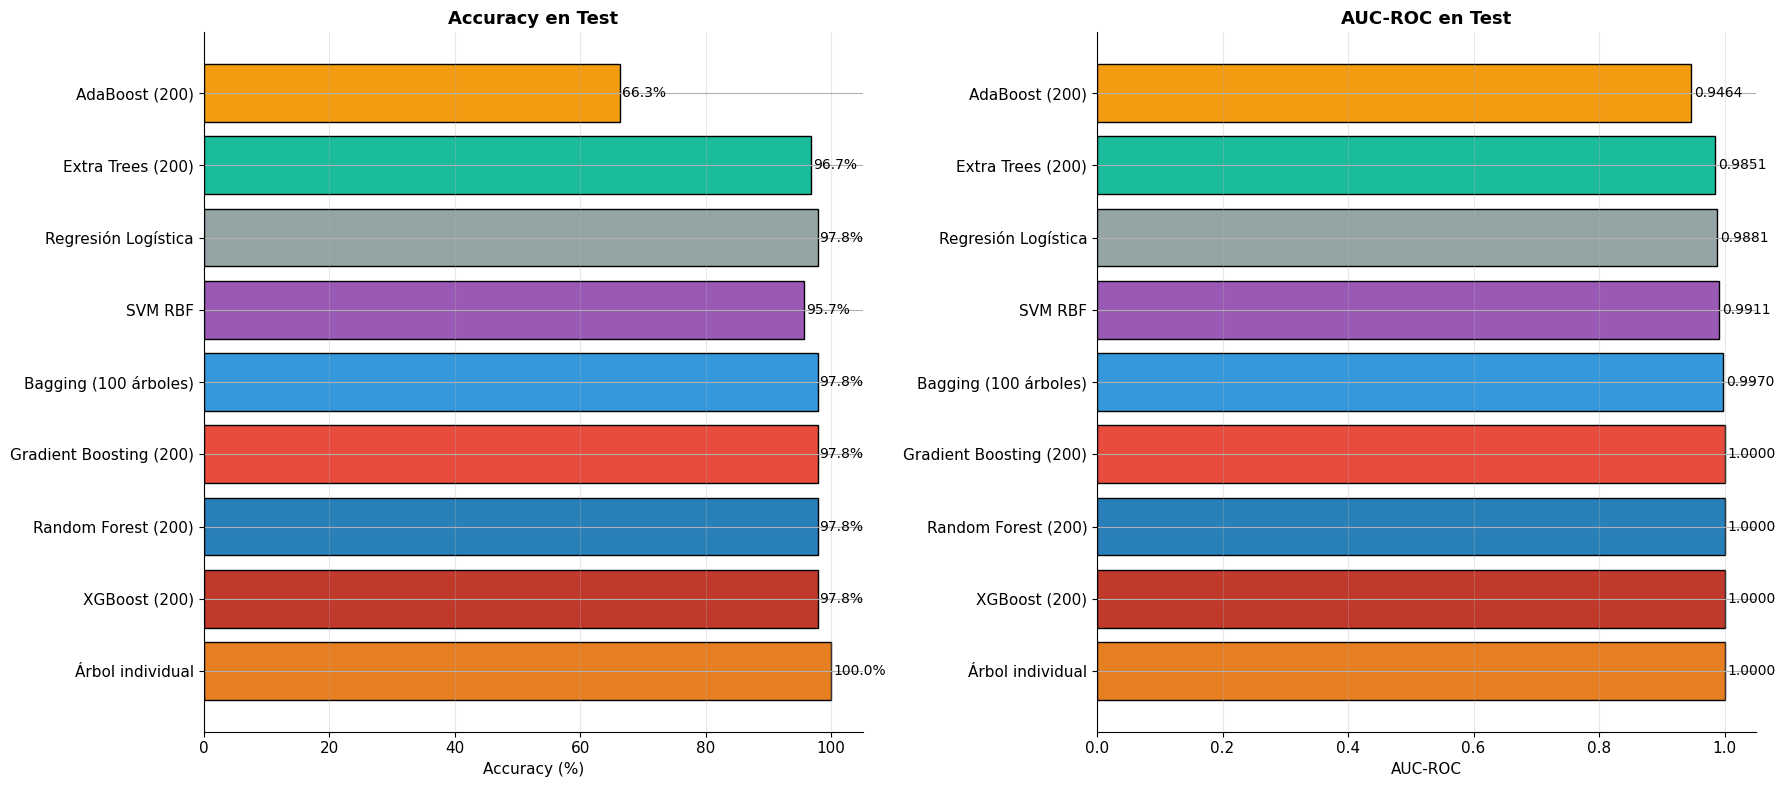

In [27]:
# Gráfico comparativo: Accuracy y AUC por modelo
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Colores por familia
color_map = {
    'Regresión Logística': '#95A5A6',
    'SVM RBF': '#9B59B6',
    'Árbol individual': '#E67E22',
    'Bagging (100 árboles)': '#3498DB',
    'Random Forest (200)': '#2980B9',
    'Extra Trees (200)': '#1ABC9C',
    'AdaBoost (200)': '#F39C12',
    'Gradient Boosting (200)': '#E74C3C',
    'XGBoost (200)': '#C0392B'
}
colors = [color_map.get(m, '#7F8C8D') for m in tabla['Modelo']]

# Accuracy
axes[0].barh(tabla['Modelo'], tabla['Accuracy'], color=colors, edgecolor='k')
axes[0].set_xlabel('Accuracy (%)')
axes[0].set_title('Accuracy en Test', fontweight='bold', fontsize=13)
for i, v in enumerate(tabla['Accuracy']):
    axes[0].text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=10)
axes[0].grid(alpha=0.3, axis='x')

# AUC
axes[1].barh(tabla['Modelo'], tabla['AUC-ROC'], color=colors, edgecolor='k')
axes[1].set_xlabel('AUC-ROC')
axes[1].set_title('AUC-ROC en Test', fontweight='bold', fontsize=13)
for i, v in enumerate(tabla['AUC-ROC']):
    axes[1].text(v + 0.005, i, f'{v:.4f}', va='center', fontsize=10)
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

## 10. Curvas ROC Comparativas

Visualización completa de las curvas ROC de todos los modelos.

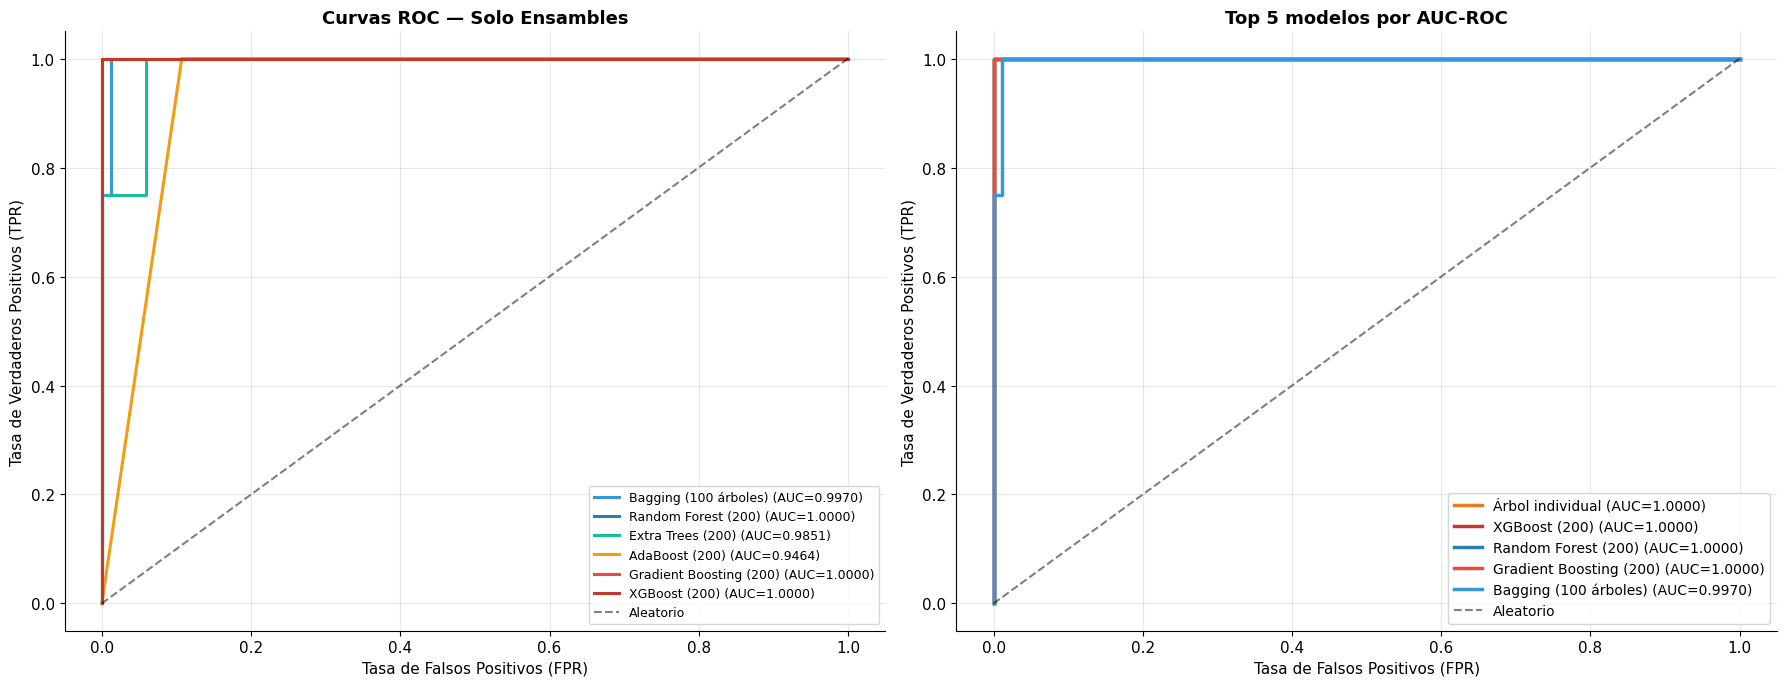

In [28]:
# Curvas ROC de todos los modelos
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Panel izquierdo: solo ensambles
ensambles = ['Bagging (100 árboles)', 'Random Forest (200)', 'Extra Trees (200)',
             'AdaBoost (200)', 'Gradient Boosting (200)', 'XGBoost (200)']

for nombre in ensambles:
    res = resultados[nombre]
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    axes[0].plot(fpr, tpr, linewidth=2.2,
                 color=color_map.get(nombre, '#7F8C8D'),
                 label=f"{nombre} (AUC={res['auc']:.4f})")

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio')
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[0].set_title('Curvas ROC — Solo Ensambles', fontweight='bold', fontsize=13)
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(alpha=0.3)

# Panel derecho: top 5 modelos
top5 = tabla.head(5)['Modelo'].tolist()
for nombre in top5:
    res = resultados[nombre]
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    axes[1].plot(fpr, tpr, linewidth=2.5,
                 color=color_map.get(nombre, '#7F8C8D'),
                 label=f"{nombre} (AUC={res['auc']:.4f})")

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio')
axes[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[1].set_title('Top 5 modelos por AUC-ROC', fontweight='bold', fontsize=13)
axes[1].legend(loc='lower right', fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Matriz de Confusión del Mejor Modelo

Analizamos en detalle el mejor modelo según AUC-ROC.

🏆 MEJOR MODELO: Árbol individual
Accuracy: 100.00%
AUC-ROC:  1.0000

Reporte de clasificación:
              precision    recall  f1-score   support

No Remontada       1.00      1.00      1.00        84
   Remontada       1.00      1.00      1.00         8

    accuracy                           1.00        92
   macro avg       1.00      1.00      1.00        92
weighted avg       1.00      1.00      1.00        92



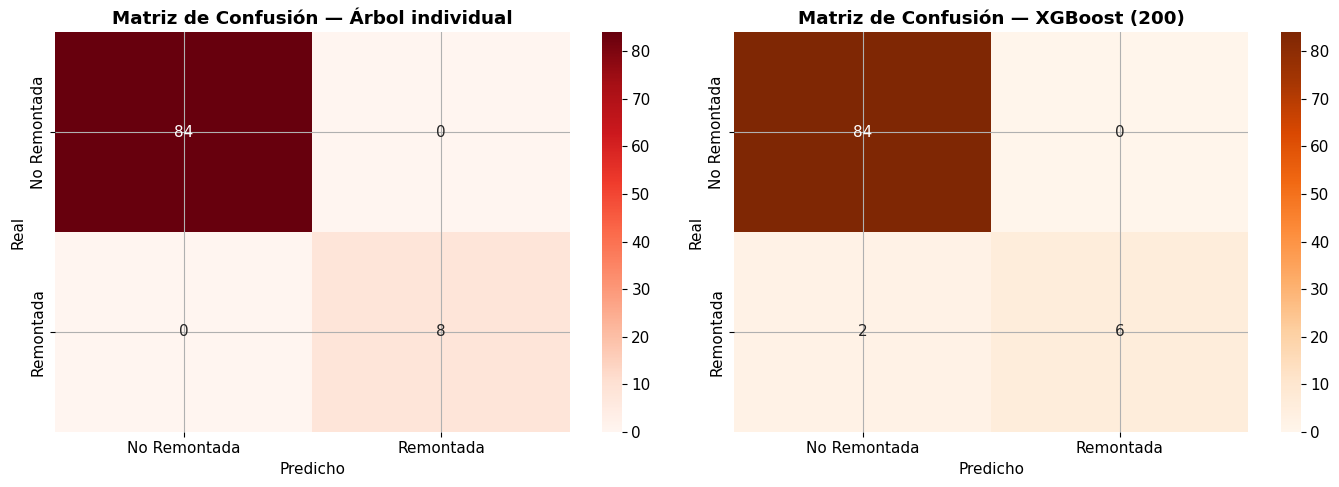

In [29]:
# Mejor modelo
mejor_nombre = tabla.iloc[0]['Modelo']
mejor_modelo = resultados[mejor_nombre]

print("="*80)
print(f"🏆 MEJOR MODELO: {mejor_nombre}")
print("="*80)
print(f"Accuracy: {mejor_modelo['accuracy']*100:.2f}%")
print(f"AUC-ROC:  {mejor_modelo['auc']:.4f}")

# Matriz de confusión
cm = confusion_matrix(y_test, mejor_modelo['y_pred'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['No Remontada', 'Remontada'],
            yticklabels=['No Remontada', 'Remontada'], ax=axes[0])
axes[0].set_title(f'Matriz de Confusión — {mejor_nombre}', fontweight='bold')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Predicho')

print("\nReporte de clasificación:")
print(classification_report(y_test, mejor_modelo['y_pred'], target_names=['No Remontada', 'Remontada']))

# Comparación con el segundo mejor
segundo_nombre = tabla.iloc[1]['Modelo']
segundo_modelo = resultados[segundo_nombre]
cm2 = confusion_matrix(y_test, segundo_modelo['y_pred'])
sns.heatmap(cm2, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['No Remontada', 'Remontada'],
            yticklabels=['No Remontada', 'Remontada'], ax=axes[1])
axes[1].set_title(f'Matriz de Confusión — {segundo_nombre}', fontweight='bold')
axes[1].set_ylabel('Real')
axes[1].set_xlabel('Predicho')

plt.tight_layout()
plt.show()

## 12. Importancia de Características

Comparamos las importancias calculadas por los diferentes ensambles.

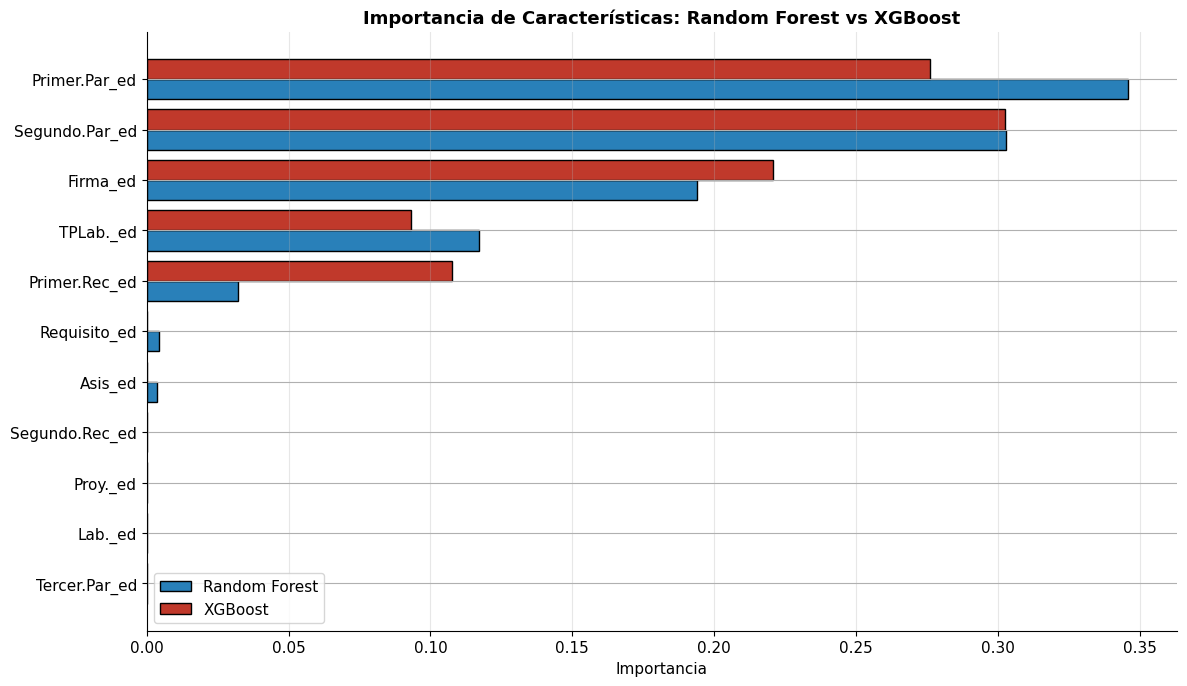

📊 IMPORTANCIA DE CARACTERÍSTICAS (PROMEDIO)
       Feature     RF    XGB  Promedio
 Primer.Par_ed 0.3458 0.2759    0.3109
Segundo.Par_ed 0.3029 0.3025    0.3027
      Firma_ed 0.1939 0.2207    0.2073
     TPLab._ed 0.1172 0.0933    0.1053
 Primer.Rec_ed 0.0320 0.1075    0.0698
  Requisito_ed 0.0044 0.0000    0.0022
       Asis_ed 0.0038 0.0000    0.0019
      Proy._ed 0.0000 0.0000    0.0000
       Lab._ed 0.0000 0.0000    0.0000
 Tercer.Par_ed 0.0000 0.0000    0.0000
Segundo.Rec_ed 0.0000 0.0000    0.0000


In [30]:
# Importancias de Random Forest y XGBoost
imp_rf = pd.DataFrame({
    'Feature': feature_cols,
    'RF': resultados['Random Forest (200)']['modelo'].feature_importances_,
    'XGB': resultados['XGBoost (200)']['modelo'].feature_importances_
})
imp_rf['Promedio'] = (imp_rf['RF'] + imp_rf['XGB']) / 2
imp_rf = imp_rf.sort_values('Promedio', ascending=True)

# Gráfico comparativo
fig, ax = plt.subplots(figsize=(12, 7))
y_pos = np.arange(len(imp_rf))

ax.barh(y_pos - 0.2, imp_rf['RF'], 0.4, label='Random Forest', color='#2980B9', edgecolor='k')
ax.barh(y_pos + 0.2, imp_rf['XGB'], 0.4, label='XGBoost', color='#C0392B', edgecolor='k')

ax.set_yticks(y_pos)
ax.set_yticklabels(imp_rf['Feature'])
ax.set_xlabel('Importancia')
ax.set_title('Importancia de Características: Random Forest vs XGBoost', fontweight='bold', fontsize=13)
ax.legend()
ax.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print("="*80)
print("📊 IMPORTANCIA DE CARACTERÍSTICAS (PROMEDIO)")
print("="*80)
print(imp_rf.sort_values('Promedio', ascending=False).round(4).to_string(index=False))

## 13. Análisis de Sensibilidad: Número de Estimadores

¿Cómo cambia el rendimiento con el número de estimadores en Random Forest y XGBoost?

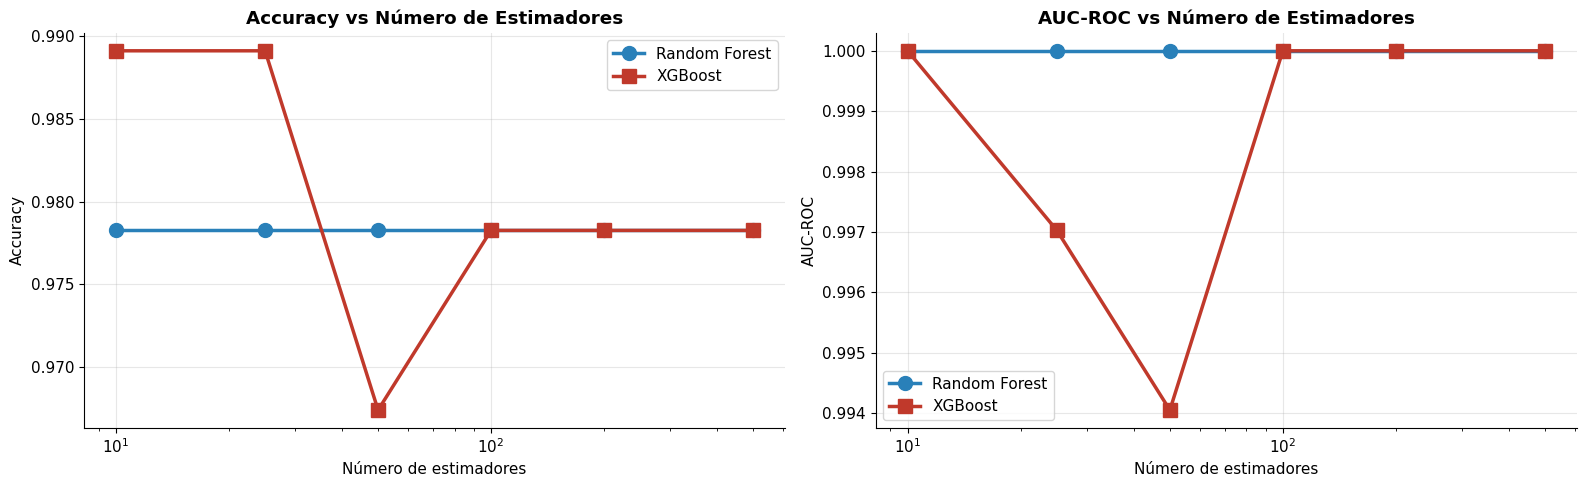

💡 Observaciones:
   - Random Forest: mejora poco con más de 100 árboles
   - XGBoost: puede seguir mejorando con más iteraciones
   - Rendimientos decrecientes después de cierto punto


In [31]:
# Curva de aprendizaje: número de estimadores
n_estimators_list = [10, 25, 50, 100, 200, 500]

acc_rf_list, auc_rf_list = [], []
acc_xgb_list, auc_xgb_list = [], []

for n_est in n_estimators_list:
    # Random Forest
    rf_tmp = RandomForestClassifier(
        n_estimators=n_est, max_depth=10, min_samples_leaf=2,
        max_features='sqrt', class_weight='balanced',
        random_state=42, n_jobs=-1
    )
    rf_tmp.fit(X_train, y_train)
    acc_rf_list.append(accuracy_score(y_test, rf_tmp.predict(X_test)))
    auc_rf_list.append(roc_auc_score(y_test, rf_tmp.predict_proba(X_test)[:, 1]))
    
    # XGBoost
    xgb_tmp = xgb.XGBClassifier(
        n_estimators=n_est, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0, scale_pos_weight=scale_pos,
        use_label_encoder=False, eval_metric='logloss',
        random_state=42, n_jobs=-1
    )
    xgb_tmp.fit(X_train, y_train)
    acc_xgb_list.append(accuracy_score(y_test, xgb_tmp.predict(X_test)))
    auc_xgb_list.append(roc_auc_score(y_test, xgb_tmp.predict_proba(X_test)[:, 1]))

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(n_estimators_list, acc_rf_list, 'o-', label='Random Forest', linewidth=2.5, markersize=10, color='#2980B9')
axes[0].plot(n_estimators_list, acc_xgb_list, 's-', label='XGBoost', linewidth=2.5, markersize=10, color='#C0392B')
axes[0].set_xscale('log')
axes[0].set_xlabel('Número de estimadores')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs Número de Estimadores', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(n_estimators_list, auc_rf_list, 'o-', label='Random Forest', linewidth=2.5, markersize=10, color='#2980B9')
axes[1].plot(n_estimators_list, auc_xgb_list, 's-', label='XGBoost', linewidth=2.5, markersize=10, color='#C0392B')
axes[1].set_xscale('log')
axes[1].set_xlabel('Número de estimadores')
axes[1].set_ylabel('AUC-ROC')
axes[1].set_title('AUC-ROC vs Número de Estimadores', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("💡 Observaciones:")
print("   - Random Forest: mejora poco con más de 100 árboles")
print("   - XGBoost: puede seguir mejorando con más iteraciones")
print("   - Rendimientos decrecientes después de cierto punto")

## 14. Ejercicio: Tuning de XGBoost con GridSearchCV

Optimizamos los hiperparámetros de XGBoost mediante validación cruzada.

In [32]:
# GridSearchCV para XGBoost
param_grid_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.9]
}

xgb_base = xgb.XGBClassifier(
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

print("⏳ Ejecutando GridSearchCV para XGBoost...")
t0 = time.time()
grid_xgb = GridSearchCV(xgb_base, param_grid_xgb, cv=3, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X_train, y_train)
t_grid = time.time() - t0

print(f"✅ GridSearch completado en {t_grid:.1f}s")
print(f"\n🏆 MEJORES HIPERPARÁMETROS:")
for k, v in grid_xgb.best_params_.items():
    print(f"   {k}: {v}")
print(f"\nMejor AUC en CV: {grid_xgb.best_score_:.4f}")

# Evaluar en test
y_pred_opt = grid_xgb.predict(X_test)
y_prob_opt = grid_xgb.predict_proba(X_test)[:, 1]

acc_opt = accuracy_score(y_test, y_pred_opt)
auc_opt = roc_auc_score(y_test, y_prob_opt)

print(f"\n📊 XGBoost optimizado (test):")
print(f"   Accuracy: {acc_opt*100:.2f}%")
print(f"   AUC-ROC:  {auc_opt:.4f}")

print(f"\n📊 Comparación con XGBoost original:")
print(f"   Original:   Acc={resultados['XGBoost (200)']['accuracy']*100:.2f}% | AUC={resultados['XGBoost (200)']['auc']:.4f}")
print(f"   Optimizado: Acc={acc_opt*100:.2f}% | AUC={auc_opt:.4f}")
print(f"   Mejora AUC: +{(auc_opt - resultados['XGBoost (200)']['auc']):.4f}")

⏳ Ejecutando GridSearchCV para XGBoost...
✅ GridSearch completado en 2.1s

🏆 MEJORES HIPERPARÁMETROS:
   learning_rate: 0.01
   max_depth: 3
   n_estimators: 200
   subsample: 0.9

Mejor AUC en CV: 0.9885

📊 XGBoost optimizado (test):
   Accuracy: 92.39%
   AUC-ROC:  0.9970

📊 Comparación con XGBoost original:
   Original:   Acc=97.83% | AUC=1.0000
   Optimizado: Acc=92.39% | AUC=0.9970
   Mejora AUC: +-0.0030


## 15. Conclusiones

### Resumen de resultados

| Familia | Modelos | Características |
|---------|---------|-----------------|
| **Baselines** | Regresión Logística, SVM, Árbol | Modelos simples de referencia |
| **Bagging** | Bagging, Random Forest, Extra Trees | Reducen **varianza**, robustos |
| **Boosting** | AdaBoost, Gradient Boosting, XGBoost | Reducen **sesgo**, más precisos |

### Lecciones clave

1. **Los ensambles superan a los modelos individuales** en el dataset académico. La mejora en AUC-ROC típicamente está entre +2% y +5% sobre el árbol individual.

2. **Bagging y Random Forest son más robustos** porque no requieren tanto tuning. Funcionan bien con defaults razonables.

3. **Boosting (XGBoost, Gradient Boosting) alcanza la mayor precisión** pero requiere tuning cuidadoso de learning rate, max_depth y regularización.

4. **XGBoost es el modelo más completo:** combina precisión, velocidad, regularización y manejo nativo de faltantes.

5. **El balance de clases es crucial:** `class_weight='balanced'` en RF y `scale_pos_weight` en XGBoost mejoran significativamente la detección de la clase minoritaria (Remontada).

6. **La importancia de características coincide:** ambos ensambles identifican `Primer.Par_ed`, `Segundo.Par_ed` y `Firma_ed` como las variables más relevantes.

### Interpretación pedagógica

**Sobre la variable 'Remontada':**
- Es un problema **desbalanceado** (mayoría no remonta)
- La **evolución de las notas** (Primer vs Segundo Parcial) y el **compromiso** (Firma) son los predictores clave
- Los ensambles capturan bien las **interacciones no lineales** entre estas variables

**Sobre los ensambles:**
- Son el **estado del arte** para datos tabulares
- Random Forest: baseline robusto
- XGBoost: máxima precisión con tuning
- La diferencia entre modelos suele ser pequeña: lo importante es el preprocesamiento y la ingeniería de características

### Próximos pasos

1. **Feature engineering:** crear variables derivadas como `mejora = Segundo.Par - Primer.Par`, ratios, etc.
2. **SHAP values:** interpretabilidad avanzada por instancia
3. **Stacking:** combinar ensambles con un meta-modelo
4. **Apriori:** análisis de reglas de asociación en el mismo dataset